# Analyzing a Monte Carlo run

In `03_simple_MC_example.ipynb` we ran a Monte Carlo simulation of the Li/Ti ordering in LTO and saved it. Here we load that run and ask the questions you should ask of any MC simulation:

1. What does a trajectory record?
2. Has the energy settled down, and was the acceptance rate reasonable?
3. What are the thermal averages, and how precise are they?
4. How would a different temperature change things?
5. Which distinct low-energy structures did it find, and what makes them low in energy?

Along the way we use the package's analysis functions: `plot_trajectory` plots the energy, acceptance rate, and other recorded properties against step, and `thermal_average` averages a property over the equilibrated part of a run.

In [50]:
# Imports
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pymatgen.core import Structure

from disorder_mc import (
    PrecomputedEwald,
    load_trajectory,
    plot_trajectory,
    rolling_acceptance_rate,
    run_monte_carlo,
    sublattice_swap_policy,
    symmetrically_equivalent,
    thermal_average,
)

structures_dir = Path("../tests/test_structures")
trajectory_path = Path("mc_example_out/trajectory.json") # Written by 03_simple_MC_example.ipynb

## 1. Load the trajectory

`load_trajectory` reads a trajectory saved with `save_trajectory`. If the file is missing, run `03_simple_MC_example.ipynb` first.

In [51]:
if not trajectory_path.exists():
    raise FileNotFoundError(
        f"{trajectory_path} not found. This notebook analyzes the Monte Carlo run saved by "
        "03_simple_MC_example.ipynb, so run that notebook first (it takes under a minute)."
    )

trajectory = load_trajectory(trajectory_path)
print(f"steps: {len(trajectory.steps)} (step 0 is the starting configuration)")
print(f"parameters: {trajectory.parameters}")
print(f"random seed: {trajectory.random_seed}")

steps: 2001 (step 0 is the starting configuration)
parameters: {'temperature': 10000, 'num_steps': 2000, 'num_structures_to_save': 10, 'time_limit': None, 'max_move_attempts': 1000, 'record_structure_every': 500, 'disallowed_moves': 'reject', 'detailed_balance': True}
random seed: 0


The trajectory stores the settings the run used and its random seed, so the run can be repeated exactly. Each entry in `trajectory.steps` records one step:

In [52]:
for step in trajectory.steps[1:10]:
    print(f"step {step.step}: proposed swapping sites {step.move['site_index']} and {step.move['target_site_index']}, "
          f"proposed energy {step.properties['energy']:.2f} eV, "
          f"accepted: {step.accepted}, energy after the step {step.energy:.2f} eV")

step 1: proposed swapping sites 160 and 125, proposed energy -6003.11 eV, accepted: True, energy after the step -6003.11 eV
step 2: proposed swapping sites 144 and 122, proposed energy -5983.52 eV, accepted: False, energy after the step -6003.11 eV
step 3: proposed swapping sites 123 and 125, proposed energy -5985.15 eV, accepted: False, energy after the step -6003.11 eV
step 4: proposed swapping sites 151 and 160, proposed energy -6004.77 eV, accepted: True, energy after the step -6004.77 eV
step 5: proposed swapping sites 144 and 124, proposed energy -5980.87 eV, accepted: False, energy after the step -6004.77 eV
step 6: proposed swapping sites 150 and 124, proposed energy -5962.42 eV, accepted: False, energy after the step -6004.77 eV
step 7: proposed swapping sites 133 and 127, proposed energy -5974.93 eV, accepted: False, energy after the step -6004.77 eV
step 8: proposed swapping sites 138 and 127, proposed energy -5969.24 eV, accepted: False, energy after the step -6004.77 eV
st

Two energies are recorded for each step:

- `step.properties` holds the properties of the *proposed* configuration, including its energy.
- `step.energy` is the energy of the *current* configuration after the accept/reject decision. If the move was rejected, it is the same as the previous step's.

The analysis functions below always report the *current* configuration. For a property other than the energy, they carry its value forward from the last accepted step (`property_series` returns this series directly).

## 2. Has the energy settled down? Was the acceptance rate reasonable?

A run starts from a random configuration with a high energy. The energy then drops as the simulation finds better configurations, and eventually fluctuates around a steady average. The early downhill part is called *equilibration*. Only the steady part afterwards represents the system at that temperature, so averages should be taken over that part only.

The *acceptance rate* is the fraction of proposed moves that were accepted. It's a quick check on the temperature:

- **Very low** (well under 1%): the simulation is nearly frozen and barely moves.
- **Very high** (over about 50%): almost every move is accepted, so the energy barely matters and the simulation is close to random sampling.

`plot_trajectory` shows both against step, with the acceptance rate taken over a sliding window of moves (`window=100` by default). Other recorded properties can be added as panels of their own by naming them in `properties` (section 4). `acceptance_rate=False` drops the acceptance-rate panel, and `height_ratios` sets the relative panel heights.

Text(0.5, 0, 'Step Number')

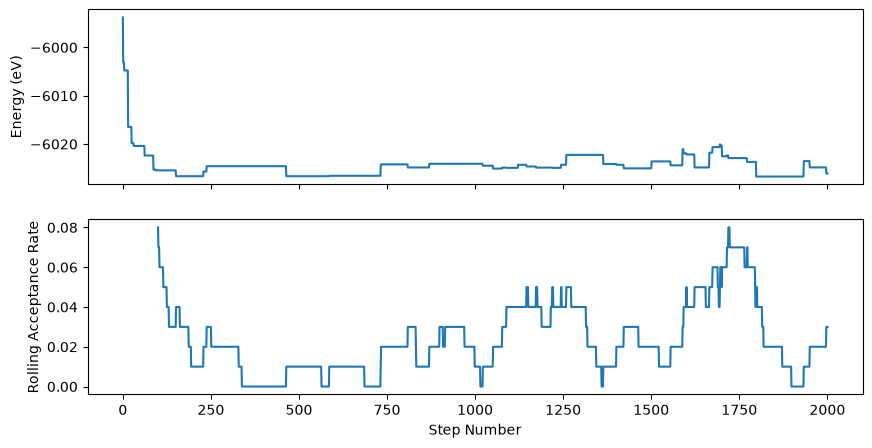

In [53]:
steps=np.array([step.step for step in trajectory.steps])
energies=np.array([step.energy for step in trajectory.steps])
rate_steps, acceptance_rates=rolling_acceptance_rate(trajectory)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(10,5))
axes[0].plot(steps, energies)
axes[0].set_ylabel("Energy (eV)")
axes[1].plot(rate_steps, acceptance_rates, )
axes[1].set_ylabel("Rolling Acceptance Rate")
axes[1].set_xlabel("Step Number")


There is also a built-in plot_trajectory function that does the same as above

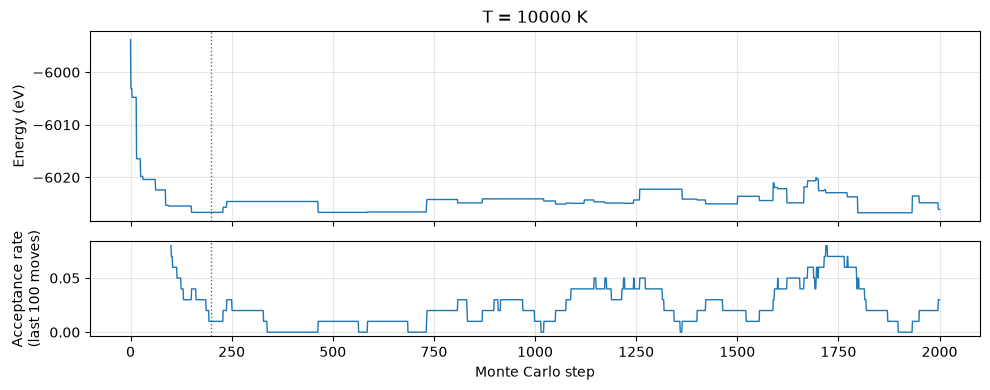

In [54]:
fig = plot_trajectory(trajectory,
                      figsize=(10, 4), 
                      equilibration_steps=200, # Draw a line when equillibriuated. Value chosen by eye.
                      height_ratios=(2,1) #Make the energy plot 2x taller than the acceptance rate plot
                    )
plt.show()

The energy drops by about 30 eV in the first 100 or so steps and then fluctuates within a few eV. We chose step 200 (the dotted line) as the end of equilibration by looking at the plot. There's no exact rule; when in doubt, discard a bit too much rather than too little. A run that is still drifting downhill at the end hasn't equilibrated, and needs more steps.

Acceptance is highest at the start, when many swaps lead downhill. After that it varies between 0 and about 8%. In stretches where the simulation sits in a low-energy configuration, every swap leads uphill and almost all are rejected. In stretches where it wanders among slightly higher-energy configurations, more moves are accepted. Overall it's low but not frozen: the simulation still moves every few dozen steps.

## 3. Thermal averages

A Metropolis simulation visits each configuration in proportion to its Boltzmann probability, so the thermal average of a property at the run's temperature is simply its mean over the steps after equilibration. Rejected steps count too: a rejection means the simulation stays where it is, and that configuration is counted again.

Successive steps are strongly correlated (most steps don't change the configuration at all), so the standard deviation of the steps says nothing about how precise the mean is. `thermal_average` estimates the uncertainty by *batch means*: it splits the steps into blocks (20 by default), averages each block, and uses the scatter of the block averages. This works only if each block is much longer than the time the simulation takes to forget where it was.

In [55]:
equilibration_steps=200
energy_average = thermal_average(trajectory, "energy", equilibration_steps=equilibration_steps)
print(energy_average)
print()

# The uncertainty estimate should not depend much on the number of blocks.
for n_blocks in [5, 10, 15, 20, 50]:
    estimate = thermal_average(trajectory, equilibration_steps=equilibration_steps, n_blocks=n_blocks)
    print(f"{n_blocks:>3} blocks of {estimate.n_samples // n_blocks:>3} steps: standard error {estimate.standard_error:.2f} eV")

<energy> at 10000 K = -6024.69 +/- 0.27 (std 1.41, 1801 steps)

  5 blocks of 360 steps: standard error 0.32 eV
 10 blocks of 180 steps: standard error 0.34 eV
 15 blocks of 120 steps: standard error 0.29 eV
 20 blocks of  90 steps: standard error 0.27 eV
 50 blocks of  36 steps: standard error 0.19 eV


The energy fluctuates by about 1.4 eV from step to step (`std`), but the mean is known more precisely than that. The error estimate is fairly stable from 5 to 20 blocks and shrinks with 50 blocks of 36 steps. Blocks that short are not much longer than the stretches the simulation spends stuck in one configuration, so they underestimate the error. If the estimate keeps changing as the blocks get longer, the run is too short for a reliable error bar.

`thermal_average` also checks that the averaged steps were all run at one temperature. It warns if the trajectory doesn't record that the policy satisfies detailed balance, since only then is the plain mean a Boltzmann average. `sublattice_swap_policy` does satisfy it.

## 4. How does temperature change things?

To see the effect of temperature, we rerun the same simulation from the same starting configuration at three temperatures: the original 10,000 K, one lower, and one higher. The trajectory stored the starting configuration as `trajectory.steps[0].structure`. We rebuild the parent and policy the same way as in `03_simple_MC_example.ipynb`.

This time the policy also records two structural properties at every step, as simple measures of Li/Ti order on the mixed (16d) sites: the number of Li-Li pairs on neighboring mixed sites (`li_li_pairs`, about 3 A apart), and the number on second-neighbor mixed sites (`li_li_second_pairs`, about 5.1 A apart). Both put two Li+ close together where Ti4+ could be, which the Ewald energy penalizes. Its `evaluate_props` returns the energy plus these two counts. The extra property doesn't change the simulation itself, so the 10,000 K run repeats the original run step for step.

In [56]:
def count_li_li_neighbors(structure):
    """Number of Li-Li pairs closer than 3 A, i.e. Li on neighboring mixed (16d) sites."""
    li = [i for i, site in enumerate(structure) if site.specie.symbol == "Li"]
    distances = structure.distance_matrix[np.ix_(li, li)]
    return int(((distances > 0.1) & (distances < 3.0)).sum() // 2) # Each pair appears twice in the matrix


lto = Structure.from_file(structures_dir / "LTO_COD_1001098.cif")
parent = lto.get_primitive_structure() # The smallest cell that repeats to build the crystal: 14 sites
parent.make_supercell([2, 2, 3]) # 2 x 2 x 3 copies of it: 168 sites
ewald = PrecomputedEwald(parent)
mixed_coords = np.array([site.frac_coords for site in parent if not site.is_ordered]) # The 48 mixed Li/Ti sites


def count_li_li_second_neighbors(structure):
    """Number of pairs of Li on mixed sites that are second neighbors (about 5.1 A apart)."""
    li_coords = np.array([site.frac_coords for site in structure if site.specie.symbol == "Li"])
    on_mixed = structure.lattice.get_all_distances(li_coords, mixed_coords).min(axis=1) < 0.1
    distances = structure.lattice.get_all_distances(li_coords[on_mixed], li_coords[on_mixed])
    return int(((distances > 5.0) & (distances < 5.3)).sum() // 2)


def evaluate_props(configuration, context):
    return {
        "energy": ewald.energy(configuration),
        "li_li_pairs": count_li_li_neighbors(configuration),
        "li_li_second_pairs": count_li_li_second_neighbors(configuration),
    }


policy = sublattice_swap_policy(parent, evaluate_props=evaluate_props)
initial = trajectory.steps[0].structure

runs = {}
for temperature in [3000, 10000, 30000]:
    runs[temperature] = run_monte_carlo(initial, policy, temperature=temperature, num_steps=2000, seed=0)

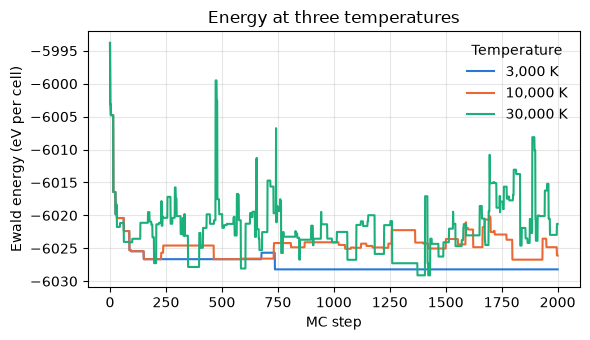

 temperature  acceptance       <energy> (eV)   <li_li_pairs>  <li_li_second_pairs>
     3,000 K       0.005   -6027.71 +/- 0.18    0.00 +/- 0.00          4.26 +/- 0.10
    10,000 K       0.025   -6024.69 +/- 0.27    0.00 +/- 0.00          6.01 +/- 0.25
    30,000 K       0.078   -6022.16 +/- 0.57    0.01 +/- 0.01          6.76 +/- 0.29


In [57]:
colors = {3000: "#2a78d6", 10000: "#eb6834", 30000: "#1baf7a"}

fig, ax = plt.subplots(figsize=(6, 3.5))
for temperature, run in runs.items():
    ax.plot(run.energies, color=colors[temperature], linewidth=1.5, label=f"{temperature:,} K")
ax.set_xlabel("MC step")
ax.set_ylabel("Ewald energy (eV per cell)")
ax.set_title("Energy at three temperatures")
ax.grid(alpha=0.3)
ax.legend(frameon=False, title="Temperature")
fig.tight_layout()
plt.show()

print(f"{'temperature':>12}  {'acceptance':>10}  {'<energy> (eV)':>18}  {'<li_li_pairs>':>14}  {'<li_li_second_pairs>':>20}")
for temperature, run in runs.items():
    energy = thermal_average(run, "energy", equilibration_steps=equilibration_steps)
    pairs = thermal_average(run, "li_li_pairs", equilibration_steps=equilibration_steps)
    second = thermal_average(run, "li_li_second_pairs", equilibration_steps=equilibration_steps)
    print(f"{temperature:>10,} K  {run.acceptance_rate():>10.3f}  {energy.mean:>9.2f} +/- {energy.standard_error:.2f}"
          f"  {pairs.mean:>6.2f} +/- {pairs.standard_error:.2f}  {second.mean:>12.2f} +/- {second.standard_error:.2f}")

The policy now records `li_li_pairs` and `li_li_second_pairs`, so we can pass them to `plot_trajectory` to get a panel for each. Here is the 30,000 K run, with the energy panel drawn twice as tall:

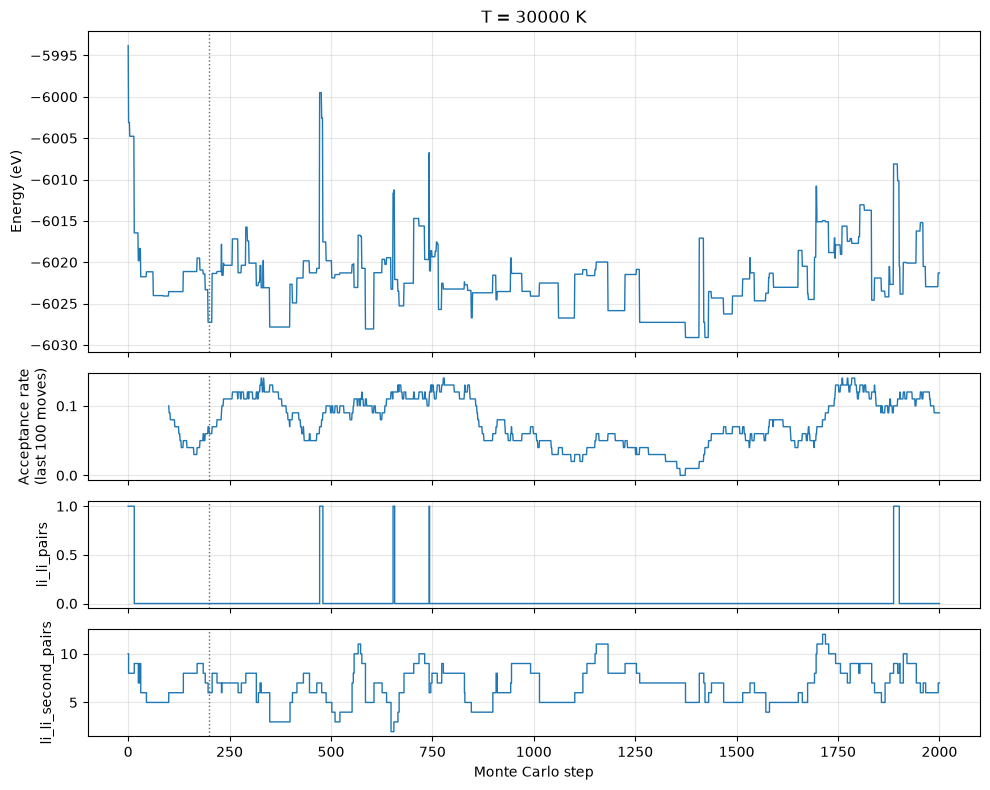

In [63]:
fig = plot_trajectory(
    runs[30000],
    figsize=(10,8),
    properties=["li_li_pairs", "li_li_second_pairs"],
    equilibration_steps=equilibration_steps,
    height_ratios=[3, 1, 1, 1], # energy, acceptance rate, li_li_pairs, li_li_second_pairs
)
plt.show()

The three runs show the trade-off from `03_simple_MC_example.ipynb`:

- At **3,000 K**, almost no uphill moves are accepted. The simulation slides downhill, and from about step 750 it stays in one configuration, a local minimum, for the rest of the run. Here it happened to get stuck in a fairly good one, so its average energy is the lowest. Its error bars mean little: the simulation sat in one configuration for most of the averaged steps, which is exactly the situation batch means cannot detect. But it can't explore any further, and from a different starting point it could just as easily get stuck somewhere worse.
- At **30,000 K**, many more moves are accepted. The simulation jumps around much more, so its average energy is the highest, and more Li pairs sit on second-neighbor mixed sites (about 6.8 on average, against 4.3 at 3,000 K). Li almost never sit on *neighboring* mixed sites at any of these temperatures: at 30,000 K such a pair appears only briefly (the spikes in the `li_li_pairs` panel), each time costing enough energy that the simulation soon moves away again. But because it explores more, it found the lowest-energy configuration of the three runs.
- **10,000 K** sits in between.

A common way to get the best of both is *simulated annealing*: start hot so the simulation explores widely, then lower the temperature step by step so it settles into a low-energy configuration. You can do this with `resume_monte_carlo`, which continues a run from a saved checkpoint, at a new temperature each time.

## 5. The lowest-energy configurations

The trajectory kept the 10 lowest-energy configurations seen during the original run. Many of them can be the same structure: the simulation can visit a configuration more than once, and it can also reach symmetric copies of the same structure (section 3 of `01_disordered_structure_tools.ipynb`). `symmetrically_equivalent` lets us group them:

In [59]:
saved = trajectory.lowest_energy_saved() # Sorted from lowest to highest energy

groups = [] # Each group is a list of saved configurations that are the same structure
for config in saved:
    for group in groups:
        if symmetrically_equivalent(config.structure, group[0].structure):
            group.append(config)
            break
    else:
        groups.append([config])

print(f"{len(saved)} saved configurations -> {len(groups)} distinct structures")
for group in groups:
    steps = ", ".join(str(config.step) for config in group)
    print(f"  energy {group[0].energy:.2f} eV, found {len(group)} time(s), at steps {steps}")

10 saved configurations -> 5 distinct structures
  energy -6026.72 eV, found 1 time(s), at steps 1798
  energy -6026.65 eV, found 2 time(s), at steps 151, 464
  energy -6026.57 eV, found 1 time(s), at steps 586
  energy -6026.10 eV, found 1 time(s), at steps 1997
  energy -6025.68 eV, found 5 time(s), at steps 159, 162, 229, 507, 539


What makes these configurations low in energy? In the random sampling notebook, the lowest-energy configurations had no Li on neighboring mixed sites. Let's check these:

In [60]:
print(f"starting configuration: energy {trajectory.energies[0]:.2f} eV, {count_li_li_neighbors(initial)} Li-Li neighbor pairs")
for group in groups:
    print(f"distinct structure:     energy {group[0].energy:.2f} eV, {count_li_li_neighbors(group[0].structure)} Li-Li neighbor pairs")

starting configuration: energy -5993.81 eV, 1 Li-Li neighbor pairs
distinct structure:     energy -6026.72 eV, 0 Li-Li neighbor pairs
distinct structure:     energy -6026.65 eV, 0 Li-Li neighbor pairs
distinct structure:     energy -6026.57 eV, 0 Li-Li neighbor pairs
distinct structure:     energy -6026.10 eV, 0 Li-Li neighbor pairs
distinct structure:     energy -6025.68 eV, 0 Li-Li neighbor pairs


The random starting configuration had a pair of Li on neighboring mixed sites, and none of the low-energy structures does. Keeping the Li apart spreads the positive charge more evenly through the crystal, which is what the Ewald energy rewards. The structures still differ in how the Li are arranged beyond nearest neighbors, which accounts for their small energy differences.

## Summary

- A trajectory records the settings and random seed, and for every step the proposed move, its energy, whether it was accepted, and the current energy. It also keeps the lowest-energy configurations seen.
- `plot_trajectory` plots energy, acceptance rate (optional), and any other recorded properties you name against step. Use it to check equilibration, and only average over the part after it.
- The acceptance rate is a quick check on the temperature: too low means the simulation is frozen, too high means the energy barely matters.
- `thermal_average` gives the thermal average of a property over the equilibrated steps, with a batch-means error bar. Check that the error bar is stable as the number of blocks changes.
- Temperature trades exploring against settling into low energies. Simulated annealing uses both.
- Saved configurations often include repeats and symmetric copies; group them with `symmetrically_equivalent` to find the distinct structures.

To go further, `demos/li4ti5o12_short_range_order` runs long MC simulations of this system at many temperatures to measure how the Li/Ti short-range order changes with temperature.